# Task 30 - Logistic Regression: Will a Product Be Recommended?

**Goal:** predict whether a product is **recommended** with Logistic Regression, using feature engineering, **class balancing (SMOTE or undersampling)** and **regularization for interpretability**.

**Data mapping:** the data has no `recommended` flag (no reviewers). A product counts as **recommended** when its average `rating` is in the top `1 - RECOMMEND_QUANTILE` (default: top 30%) among products with at least `MIN_RATINGS` ratings. The cut-off is computed from the data (printed below; set `FIXED_THRESHOLD = 4.0` to use a fixed star value instead). Products with few ratings are dropped from this task because their averages are noisy.

**Leakage control:** popularity columns (`units_sold`, `rating_count`, vote counts) and everything built from ratings or trained on them (`rs_*`, `rating_sentiment*`, `sentiment_*`, `tf_*`, engagement, `te_*`) are excluded. Only **engineered product attributes** are used: pricing, discount, shipping, merchant quality, title wording, category and tag structure, so the model answers "what kinds of listings end up recommended?".

**Design**
1. Feature engineering (ratios, logs, relative-to-category price, interactions, binary flags)
2. Balancing compared **inside CV** (never before splitting): none, `class_weight`, SMOTE, random undersampling, SMOTE + undersampling
3. Regularization: L1 (sparse), L2, Elastic Net; C tuned by grid search on PR-AUC
4. **Interpretability-first selection:** among configurations within 1 SE of the best PR-AUC, pick the one with the fewest non-zero coefficients
5. Hold-out evaluation, threshold tuning (on train OOF only), calibration, odds ratios with bootstrap CIs, comparison with a black-box reference

**Input:** newest file in `data/processed/` (missing columns borrowed from raw). **Outputs:** `data/processed/womens_clothing_recommendation_features.csv`, `reports/task_30_balancing_comparison.csv`, `task_30_model_metrics.csv`, `task_30_logistic_coefficients.csv`, `task_30_threshold_analysis.csv`, `task_30_analysis_status.csv`

In [1]:
import re, warnings
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

def find_project_root():
    """Walk up from the notebook folder until a folder containing data/processed is found."""
    start = Path.cwd().resolve()
    for cand in [start, *start.parents]:
        if (cand / "data" / "processed").exists():
            return cand
    return start.parent

ROOT = find_project_root()
PROC, REPORTS = ROOT / "data" / "processed", ROOT / "reports"
RAW = ROOT / "data" / "raw" / "womens_clothing.csv"
PROC.mkdir(parents=True, exist_ok=True); REPORTS.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

def _norm(s):
    return re.sub(r"[^a-z0-9]", "", str(s).lower())

def pick(df, *candidates, required=True):
    """Return the real column name matching any candidate (ignores case, spaces, underscores)."""
    lookup = {_norm(c): c for c in df.columns}
    for cand in candidates:
        if _norm(cand) in lookup:
            return lookup[_norm(cand)]
    if required:
        raise KeyError(f"None of {candidates} found. Columns: {list(df.columns)}")
    return None

def load_first(*paths):
    """Load the first existing CSV, so each task builds on the newest previous output."""
    for p in paths:
        if Path(p).exists():
            d = pd.read_csv(p)
            d = d.loc[:, ~d.columns.str.startswith("Unnamed")]
            print(f"Loaded: {Path(p).name}  shape={d.shape}")
            return d, Path(p)
    raise FileNotFoundError("None of these files exist: " + ", ".join(str(p) for p in paths))

def add_from_raw(df, *names):
    """Borrow columns missing from df (e.g. title, tags) from data/raw, matched on product_id."""
    missing = [n for n in names if pick(df, n, required=False) is None]
    if not missing:
        return df
    raw = pd.read_csv(RAW); raw = raw.loc[:, ~raw.columns.str.startswith("Unnamed")]
    kd, kr = pick(df, "product_id", required=False), pick(raw, "product_id", required=False)
    if kd is None or kr is None:
        raise KeyError(f"Need product_id in both files to borrow {missing} from raw")
    got = [pick(raw, n) for n in missing if pick(raw, n, required=False)]
    if not got:
        raise KeyError(f"{missing} not found in raw file either")
    add = raw.drop_duplicates(kr)[[kr] + got].rename(columns={kr: kd})
    out = df.merge(add, on=kd, how="left")
    print("Borrowed from raw:", got)
    return out

# Newest cumulative dataset first; each task reads the newest file produced BEFORE it.
CHAIN = ["womens_clothing_high_cardinality_encoded.csv", "womens_clothing_engagement_features.csv",
         "womens_clothing_sentiment_features.csv", "womens_clothing_age_segmented.csv",
         "womens_clothing_review_text_features.csv", "womens_clothing_market_basket_features.csv",
         "womens_clothing_product_text_features.csv", "womens_clothing_product_tag_features.csv",
         "womens_clothing_product_segmented.csv", "womens_clothing_final.csv"]

# Tasks 19-21 outputs sit in front of the older chain.
LATE = ["womens_clothing_lifecycle_features.csv", "womens_clothing_tfidf_features.csv", "womens_clothing_channel_interaction_features.csv"]
FULL = LATE + CHAIN

# Tasks 22-24 outputs sit in front of everything.
LATE2 = ["womens_clothing_rating_sentiment_encoded.csv", "womens_clothing_pca_features.csv"]
ALL = LATE2 + FULL

REG_DATASET = "womens_clothing_regression_dataset.csv"      # written by Task 25, read by Tasks 26-27

import time
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, train_test_split, cross_val_predict
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score, recall_score, balanced_accuracy_score, matthews_corrcoef,
                             brier_score_loss, confusion_matrix, precision_recall_curve, roc_curve)
sns.set_theme(style="whitegrid"); pd.set_option("display.max_columns", 60)
RANDOM_STATE = 42
RECOMMEND_QUANTILE = 0.70       # recommended = rating in the top 30% of reliably rated products
FIXED_THRESHOLD = None          # e.g. 4.0 to override the data-driven cut-off
MIN_RATINGS = 20
C_GRID = np.logspace(-3, 1, 9)

Project root: D:\OneDrive\Desktop\Brainybeams\Womens_Clothing_ML_Project


## 1. Load data and define the target

Loaded: womens_clothing_rating_sentiment_encoded.csv  shape=(1539, 155)
Reliably rated products: 1,211 (rating_count >= 20) | recommended threshold: rating >= 4.040 | recommended share 30.8% (imbalance 2.2:1)


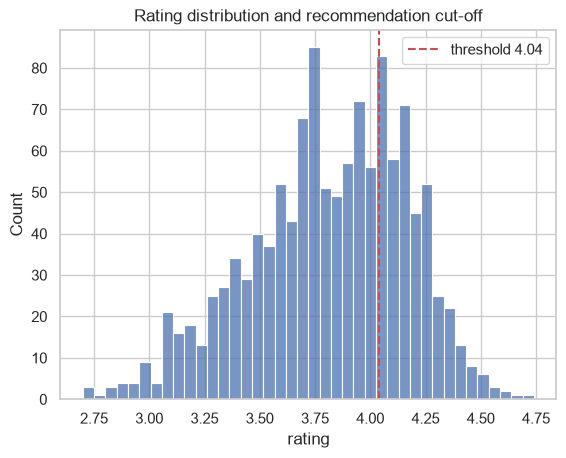

In [2]:
df, src = load_first(*[PROC / n for n in ALL])
df = add_from_raw(df, "title", "tags")
rating_col = pick(df, "rating"); rc_col = pick(df, "rating_count"); id_col = pick(df, "product_id", required=False)
rel = df[rc_col] >= MIN_RATINGS
thr = FIXED_THRESHOLD if FIXED_THRESHOLD is not None else float(df.loc[rel, rating_col].quantile(RECOMMEND_QUANTILE))
df = df[rel].reset_index(drop=True)
y = (df[rating_col] >= thr).astype(int); y.name = "recommended"
print(f"Reliably rated products: {len(df):,} (rating_count >= {MIN_RATINGS}) | recommended threshold: rating >= {thr:.3f} | recommended share {y.mean():.1%} (imbalance {(1 - y.mean()) / y.mean():.1f}:1)")
sns.histplot(df[rating_col], bins=40, color="#4c72b0"); plt.axvline(thr, color="r", ls="--", label=f"threshold {thr:.2f}"); plt.legend(); plt.title("Rating distribution and recommendation cut-off"); plt.show()

## 2. Feature engineering

| Feature | Idea |
|---|---|
| `log_price`, `log_retail_price`, `discount_pct`, `price_to_retail` | price level and perceived deal |
| `price_rel_category` | price divided by the category median (premium vs cheap *for its category*) |
| `ship_to_price` | shipping cost relative to price |
| `merchant_rating`, `log_merchant_ratings`, `merchant_quality_x_size` | seller quality and scale, plus their interaction |
| `uses_ad_boosts`, `badges_count`, `has_urgency`, `express_shipping` | marketing / fulfilment flags |
| title: `title_words`, `title_caps_ratio`, `title_digits`, `title_exclaim`, `title_sentiment`, `title_keyword_stuffing` | listing wording |
| `n_tags`, `tag_rarity` | tag structure (mean inverse frequency of the product's tags) |
| category one-hot, top colours / sizes flags | product type |
| `discount_x_ads`, `premium_x_merchant` | selected interactions |

In [3]:
def num(col): 
    c = pick(df, col, required=False); return pd.to_numeric(df[c], errors="coerce") if c else pd.Series(np.nan, index=df.index)
F = pd.DataFrame(index=df.index)
price, retail = num("price"), num("retail_price")
F["log_price"] = np.log1p(price); F["log_retail_price"] = np.log1p(retail)
F["discount_pct"] = (1 - price / retail.replace(0, np.nan)).clip(-1, 1); F["price_to_retail"] = (price / retail.replace(0, np.nan)).clip(0, 3)
cat_c = pick(df, "mb_category", required=False)
if cat_c:
    F["price_rel_category"] = price / df.groupby(cat_c)[pick(df, "price")].transform("median")
    F = pd.concat([F, pd.get_dummies(df[cat_c].astype("string"), prefix="cat", dtype=int)], axis=1)
F["ship_to_price"] = (num("shipping_option_price") / price.replace(0, np.nan)).clip(0, 5)
F["merchant_rating"] = num("merchant_rating"); F["log_merchant_ratings"] = np.log1p(num("merchant_rating_count"))
F["uses_ad_boosts"] = num("uses_ad_boosts"); F["badges_count"] = num("badges_count"); F["has_urgency"] = num("has_urgency_banner").fillna(0); F["express_shipping"] = num("shipping_is_express")
title = df[pick(df, "title")].astype("string").fillna("")
F["title_words"] = title.str.split().str.len().fillna(0); F["title_caps_ratio"] = title.map(lambda t: sum(c.isupper() for c in t) / max(sum(c.isalpha() for c in t), 1))
F["title_digits"] = title.str.count(r"\d"); F["title_exclaim"] = title.str.count("!")
F["title_keyword_stuffing"] = title.map(lambda t: 1 - len(set(t.lower().split())) / max(len(t.split()), 1))
sc = pick(df, "ttl_sent_compound", required=False)
if sc: F["title_sentiment"] = pd.to_numeric(df[sc], errors="coerce")
tags = df[pick(df, "tags")].fillna("").map(lambda s: [t.strip().lower() for t in str(s).split(",") if t.strip()])
tf_ = pd.Series([t for ts in tags for t in ts]).value_counts(normalize=True)
F["n_tags"] = tags.map(len); F["tag_rarity"] = tags.map(lambda ts: np.mean([-np.log(tf_.get(t, 1e-4)) for t in ts]) if ts else 0)
col_c = pick(df, "product_color", required=False)
if col_c:
    top_col = df[col_c].astype(str).str.lower().value_counts().head(5).index
    for c in top_col: F[f"color_{re.sub('[^a-z0-9]+', '_', c)}"] = (df[col_c].astype(str).str.lower() == c).astype(int)
size_c = pick(df, "product_variation_size_id", required=False)
if size_c:
    sz = df[size_c].astype(str).str.upper().str.replace("SIZE", "").str.replace(r"[-. ]", "", regex=True)
    for s in ["XS", "S", "M", "L"]: F[f"size_{s}"] = (sz == s).astype(int)
F["merchant_quality_x_size"] = F["merchant_rating"] * F["log_merchant_ratings"]
F["discount_x_ads"] = F["discount_pct"] * F["uses_ad_boosts"]
if "price_rel_category" in F: F["premium_x_merchant"] = F["price_rel_category"] * F["merchant_rating"]
F = F.loc[:, F.notna().any() & (F.nunique() > 1)]; F = F.fillna(F.median())
print(f"{F.shape[1]} engineered features"); F.describe().T.round(3).head(12)

26 engineered features


,count,mean,std,min,25%,50%,75%,max
log_price,1211.0,2.171633,0.416635,0.693147,1.94591,2.197225,2.484907,2.983786
log_retail_price,1211.0,2.648618,0.821873,1.098612,2.079442,2.397895,3.295837,4.016383
discount_pct,1211.0,0.245975,0.3957,-0.182,-0.125,0.035,0.706422,0.963303
price_to_retail,1211.0,0.754025,0.3957,0.036697,0.293578,0.965,1.125,1.182
ship_to_price,1211.0,0.295671,0.082708,0.169492,0.25,0.285714,0.333333,1.0
merchant_rating,1211.0,4.053831,0.175811,3.034483,3.946791,4.056888,4.17085,4.577519
log_merchant_ratings,1211.0,8.97503,1.615308,3.091042,8.172444,9.192991,10.280392,10.97391
title_words,1211.0,18.947151,6.500643,5.0,15.0,18.0,22.0,54.0
title_caps_ratio,1211.0,0.120038,0.079199,0.0,0.04461,0.123077,0.186047,0.358824
title_digits,1211.0,0.983485,1.746702,0.0,0.0,0.0,1.0,15.0


In [4]:
# univariate sanity check: which engineered features separate recommended from not? (Mann-Whitney AUC; 0.5 = no signal)
from scipy.stats import mannwhitneyu
uni = pd.DataFrame({c: {"auc": roc_auc_score(y, F[c])} for c in F.columns}).T; uni["signal"] = (uni["auc"] - 0.5).abs()
uni.sort_values("signal", ascending=False).head(10).round(3)

,auc,signal
merchant_rating,0.667,0.167
tag_rarity,0.599,0.099
merchant_quality_x_size,0.564,0.064
log_retail_price,0.544,0.044
title_caps_ratio,0.539,0.039
n_tags,0.538,0.038
log_price,0.536,0.036
log_merchant_ratings,0.530,0.030
title_words,0.529,0.029
color_black,0.528,0.028


## 3. Train / hold-out split

In [5]:
Xtr, Xte, ytr, yte = train_test_split(F, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
print(f"train {len(Xtr):,} (recommended {ytr.mean():.1%}) | hold-out {len(Xte):,} (recommended {yte.mean():.1%})")

train 908 (recommended 30.8%) | hold-out 303 (recommended 30.7%)


## 4. Balancing and regularization, compared inside cross-validation

Resampling happens **only on the training folds** (imbalanced-learn pipelines), so validation folds keep the real class ratio. The grid covers three penalties and nine C values per balancing strategy; the metric is **PR-AUC** (average precision), which is more informative than accuracy when the positive class is the minority.

In [6]:
samplers = {"none": None, "class_weight": "balanced", "SMOTE": SMOTE(k_neighbors=5, random_state=RANDOM_STATE), "undersample": RandomUnderSampler(random_state=RANDOM_STATE),
            "SMOTE+undersample": "combo"}
penalties = {"L1": dict(penalty="l1", l1_ratio=None), "L2": dict(penalty="l2", l1_ratio=None), "ElasticNet": dict(penalty="elasticnet", l1_ratio=0.5)}
def build(sampler_name, pen, C):
    lr = LogisticRegression(solver="saga", C=C, max_iter=4000, tol=1e-3, random_state=RANDOM_STATE, class_weight="balanced" if sampler_name == "class_weight" else None, **{k: v for k, v in penalties[pen].items() if v is not None or k == "penalty"})
    steps = [("scale", StandardScaler())]
    if sampler_name == "SMOTE": steps.append(("res", SMOTE(k_neighbors=5, random_state=RANDOM_STATE)))
    elif sampler_name == "undersample": steps.append(("res", RandomUnderSampler(random_state=RANDOM_STATE)))
    elif sampler_name == "SMOTE+undersample": steps += [("res", SMOTE(sampling_strategy=0.6, k_neighbors=5, random_state=RANDOM_STATE)), ("res2", RandomUnderSampler(sampling_strategy=0.9, random_state=RANDOM_STATE))]
    return ImbPipeline(steps + [("lr", lr)])
rows = []; best_models = {}
t0 = time.time()
for sname in samplers:
    for pen in penalties:
        gs = GridSearchCV(build(sname, pen, 1.0), {"lr__C": C_GRID}, cv=cv, scoring="average_precision", n_jobs=-1, refit=True).fit(Xtr, ytr)
        for i, C in enumerate(gs.cv_results_["param_lr__C"]):
            fit = build(sname, pen, float(C)).fit(Xtr, ytr); nz = int((np.abs(fit.named_steps["lr"].coef_[0]) > 1e-8).sum())
            rows.append({"sampler": sname, "penalty": pen, "C": float(C), "cv_pr_auc": gs.cv_results_["mean_test_score"][i], "cv_pr_auc_sd": gs.cv_results_["std_test_score"][i], "nonzero_coefficients": nz})
        best_models[(sname, pen)] = gs.best_estimator_
grid = pd.DataFrame(rows); print(f"{len(grid)} configurations evaluated in {time.time() - t0:.0f}s")
grid.sort_values("cv_pr_auc", ascending=False).head(10).round(4)

135 configurations evaluated in 85s


,sampler,penalty,C,cv_pr_auc,cv_pr_auc_sd,nonzero_coefficients
74,SMOTE,ElasticNet,0.0100,0.5027,0.0333,4
48,class_weight,ElasticNet,0.0316,0.5024,0.0380,14
3,none,L1,0.0316,0.5017,0.0294,3
21,none,ElasticNet,0.0316,0.5006,0.0332,14
4,none,L1,0.1000,0.4998,0.0433,14
30,class_weight,L1,0.0316,0.4994,0.0315,5
20,none,ElasticNet,0.0100,0.4969,0.0371,2
47,class_weight,ElasticNet,0.0100,0.4966,0.0366,2
31,class_weight,L1,0.1000,0.4965,0.0442,16
22,none,ElasticNet,0.1000,0.4953,0.0469,20


,sampler,penalty,C,cv_pr_auc,cv_pr_auc_sd,nonzero_coefficients
0,SMOTE,ElasticNet,0.0100,0.5027,0.0333,4
1,SMOTE,L1,0.0316,0.4943,0.0390,8
2,SMOTE,L2,0.0100,0.4878,0.0466,26
3,SMOTE+undersample,ElasticNet,0.0316,0.4932,0.0406,12
4,SMOTE+undersample,L1,0.0316,0.4916,0.0346,4
5,SMOTE+undersample,L2,0.0032,0.4889,0.0501,26
6,class_weight,ElasticNet,0.0316,0.5024,0.0380,14
7,class_weight,L1,0.0316,0.4994,0.0315,5
8,class_weight,L2,0.0100,0.4920,0.0502,26
9,none,ElasticNet,0.0316,0.5006,0.0332,14


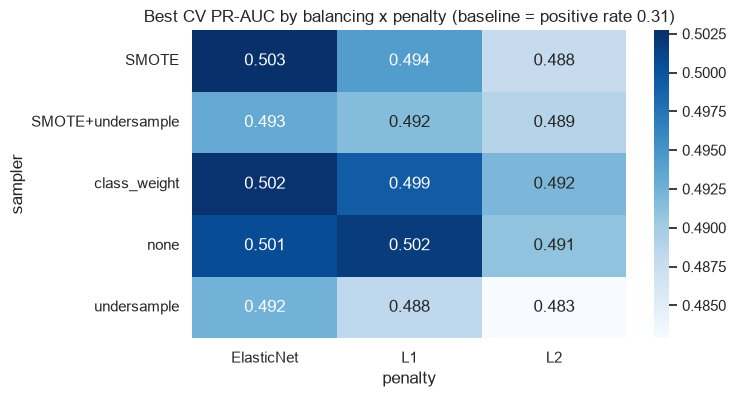

In [7]:
# Which balancing strategy helps? (best PR-AUC per strategy x penalty)
bal = grid.loc[grid.groupby(["sampler", "penalty"])["cv_pr_auc"].idxmax()].reset_index(drop=True)
display(bal.round(4))
piv = bal.pivot(index="sampler", columns="penalty", values="cv_pr_auc"); plt.figure(figsize=(7, 4)); sns.heatmap(piv, annot=True, fmt=".3f", cmap="Blues"); plt.title("Best CV PR-AUC by balancing x penalty (baseline = positive rate %.2f)" % ytr.mean()); plt.show()

## 5. Pick the final model for interpretability

1. Find the best CV PR-AUC and its standard error.
2. Keep every configuration within **1 SE** of the best.
3. Among those, choose the one with the **fewest non-zero coefficients**, ties broken by higher PR-AUC.

The best-performance configuration is kept for comparison.

Best performance : SMOTE / ElasticNet / C=0.01 -> CV PR-AUC 0.5027, 4 coefficients
Interpretable    : none / ElasticNet / C=0.01 -> CV PR-AUC 0.4969, 2 coefficients


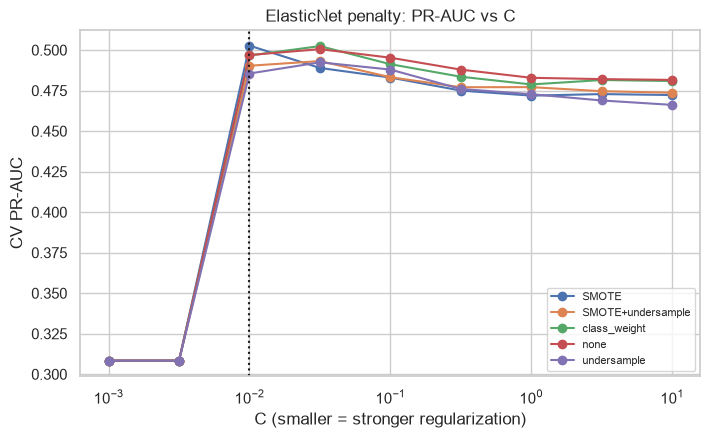

In [8]:
best = grid.loc[grid["cv_pr_auc"].idxmax()]; se = best["cv_pr_auc_sd"] / np.sqrt(5)
cand = grid[grid["cv_pr_auc"] >= best["cv_pr_auc"] - se]
final_cfg = cand.sort_values(["nonzero_coefficients", "cv_pr_auc"], ascending=[True, False]).iloc[0]
print(f"Best performance : {best['sampler']} / {best['penalty']} / C={best['C']:.4g} -> CV PR-AUC {best['cv_pr_auc']:.4f}, {int(best['nonzero_coefficients'])} coefficients")
print(f"Interpretable    : {final_cfg['sampler']} / {final_cfg['penalty']} / C={final_cfg['C']:.4g} -> CV PR-AUC {final_cfg['cv_pr_auc']:.4f}, {int(final_cfg['nonzero_coefficients'])} coefficients")
final = build(final_cfg["sampler"], final_cfg["penalty"], final_cfg["C"]).fit(Xtr, ytr)
best_perf = build(best["sampler"], best["penalty"], best["C"]).fit(Xtr, ytr)
plt.figure(figsize=(8, 4.5)); g = grid[grid["penalty"] == final_cfg["penalty"]]
for s, d in g.groupby("sampler"): plt.plot(d["C"], d["cv_pr_auc"], marker="o", label=s)
plt.xscale("log"); plt.axvline(final_cfg["C"], color="k", ls=":"); plt.xlabel("C (smaller = stronger regularization)"); plt.ylabel("CV PR-AUC"); plt.legend(fontsize=8); plt.title(f"{final_cfg['penalty']} penalty: PR-AUC vs C"); plt.show()

## 6. Threshold tuning on train out-of-fold predictions, then hold-out evaluation

F1-optimal threshold on train OOF: 0.30 (default 0.5)


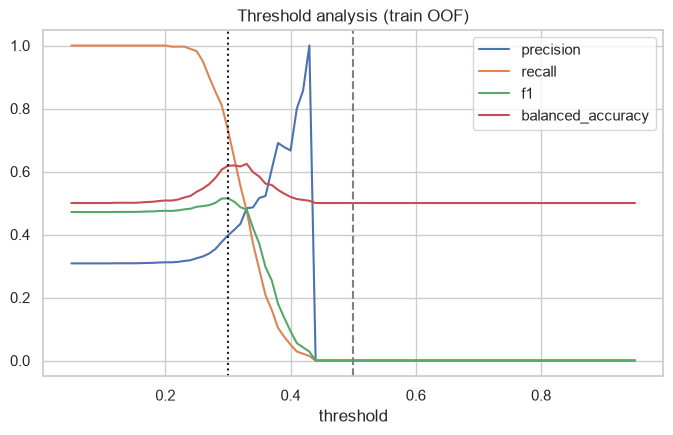

In [9]:
oof = cross_val_predict(build(final_cfg["sampler"], final_cfg["penalty"], final_cfg["C"]), Xtr, ytr, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
ths = np.linspace(0.05, 0.95, 91); rows = []
for t in ths:
    p = oof >= t; rows.append({"threshold": t, "precision": precision_score(ytr, p, zero_division=0), "recall": recall_score(ytr, p), "f1": f1_score(ytr, p), "balanced_accuracy": balanced_accuracy_score(ytr, p), "mcc": matthews_corrcoef(ytr, p)})
thr_tbl = pd.DataFrame(rows); t_star = float(thr_tbl.loc[thr_tbl["f1"].idxmax(), "threshold"])
print(f"F1-optimal threshold on train OOF: {t_star:.2f} (default 0.5)")
plt.figure(figsize=(8, 4.5)); [plt.plot(thr_tbl["threshold"], thr_tbl[m], label=m) for m in ["precision", "recall", "f1", "balanced_accuracy"]]
plt.axvline(t_star, color="k", ls=":"); plt.axvline(.5, color="grey", ls="--"); plt.legend(); plt.xlabel("threshold"); plt.title("Threshold analysis (train OOF)"); plt.show()

In [10]:
def evaluate(model, name, thr=0.5):
    p = model.predict_proba(Xte)[:, 1]; yh = p >= thr
    return {"model": name, "threshold": thr, "roc_auc": roc_auc_score(yte, p), "pr_auc": average_precision_score(yte, p), "balanced_accuracy": balanced_accuracy_score(yte, yh), "f1": f1_score(yte, yh),
            "precision": precision_score(yte, yh, zero_division=0), "recall": recall_score(yte, yh), "mcc": matthews_corrcoef(yte, yh), "brier": brier_score_loss(yte, p)}
rf = RandomForestClassifier(300, min_samples_leaf=3, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1).fit(Xtr, ytr)
metrics_tbl = pd.DataFrame([evaluate(final, f"Logistic ({final_cfg['sampler']}/{final_cfg['penalty']}) @0.5"), evaluate(final, f"Logistic ({final_cfg['sampler']}/{final_cfg['penalty']}) @tuned", t_star),
                            evaluate(best_perf, f"Logistic best-PR-AUC ({best['sampler']}/{best['penalty']}) @0.5"), evaluate(rf, "RandomForest (black-box reference) @0.5")])
metrics_tbl["positive_rate_baseline_pr_auc"] = yte.mean(); metrics_tbl.round(4)

,model,threshold,roc_auc,pr_auc,balanced_accuracy,f1,precision,recall,mcc,brier,positive_rate_baseline_pr_auc
0,Logistic (none/ElasticNet) @0.5,0.5,0.6603,0.4886,0.5000,0.0000,0.0000,0.0000,0.0000,0.2016,0.3069
1,Logistic (none/ElasticNet) @tuned,0.3,0.6603,0.4886,0.6071,0.4960,0.3949,0.6667,0.1978,0.2016,0.3069
2,Logistic best-PR-AUC (SMOTE/ElasticNet) @0.5,0.5,0.6601,0.4868,0.6207,0.4930,0.4344,0.5699,0.2269,0.2303,0.3069
3,RandomForest (black-box reference) @0.5,0.5,0.7425,0.5619,0.6545,0.5169,0.5412,0.4946,0.3171,0.1891,0.3069


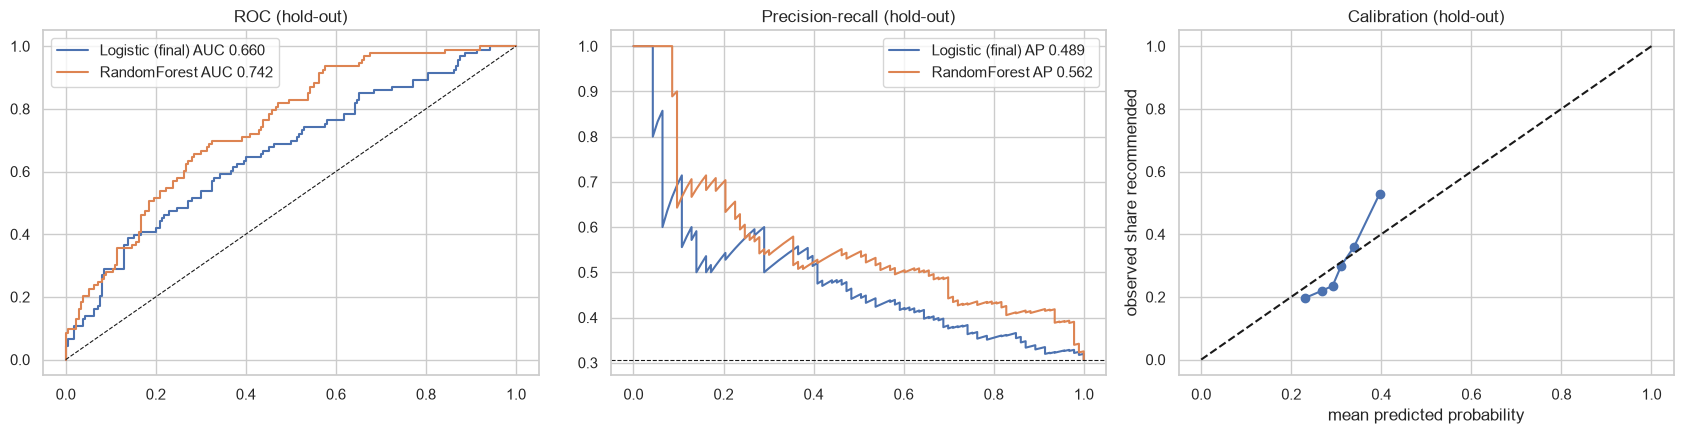

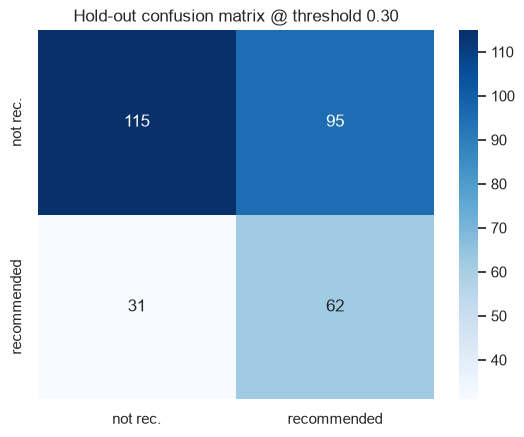

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5)); p_te = final.predict_proba(Xte)[:, 1]
for m, nm in [(final, "Logistic (final)"), (rf, "RandomForest")]:
    pp = m.predict_proba(Xte)[:, 1]; fpr, tpr, _ = roc_curve(yte, pp); ax[0].plot(fpr, tpr, label=f"{nm} AUC {roc_auc_score(yte, pp):.3f}"); pr, rc, _ = precision_recall_curve(yte, pp); ax[1].plot(rc, pr, label=f"{nm} AP {average_precision_score(yte, pp):.3f}")
ax[0].plot([0, 1], [0, 1], "k--", lw=.8); ax[0].set_title("ROC (hold-out)"); ax[0].legend(); ax[1].axhline(yte.mean(), color="k", ls="--", lw=.8); ax[1].set_title("Precision-recall (hold-out)"); ax[1].legend()
fr, mp = calibration_curve(yte, p_te, n_bins=6, strategy="quantile"); ax[2].plot(mp, fr, marker="o"); ax[2].plot([0, 1], [0, 1], "k--"); ax[2].set_title("Calibration (hold-out)"); ax[2].set_xlabel("mean predicted probability"); ax[2].set_ylabel("observed share recommended")
plt.tight_layout(); plt.show()
cm = confusion_matrix(yte, p_te >= t_star); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["not rec.", "recommended"], yticklabels=["not rec.", "recommended"]); plt.title(f"Hold-out confusion matrix @ threshold {t_star:.2f}"); plt.show()

## 7. Interpretation: coefficients, odds ratios and stability

Coefficients are per **one standard deviation** of the feature, so odds ratios are comparable across features. Confidence intervals come from 200 bootstrap refits of the *whole* pipeline (including resampling). `selection_frequency` is the share of bootstraps in which an L1 / Elastic Net model kept the feature.

In [12]:
scaler = final.named_steps["scale"]; coef = pd.Series(final.named_steps["lr"].coef_[0], index=F.columns)
rng = np.random.default_rng(RANDOM_STATE); boots = []; B = 200
for _ in range(B):
    i = rng.integers(0, len(Xtr), len(Xtr))
    if ytr.iloc[i].nunique() < 2: continue
    try: boots.append(build(final_cfg["sampler"], final_cfg["penalty"], final_cfg["C"]).fit(Xtr.iloc[i], ytr.iloc[i]).named_steps["lr"].coef_[0])
    except Exception: pass
boots = np.array(boots); lo, hi = np.percentile(boots, [2.5, 97.5], axis=0)
coef_tbl = pd.DataFrame({"coef_per_sd": coef, "odds_ratio_per_sd": np.exp(coef), "or_ci_low": np.exp(lo), "or_ci_high": np.exp(hi), "selection_frequency": (np.abs(boots) > 1e-8).mean(axis=0),
                         "ci_excludes_1": (lo > 0) | (hi < 0), "univariate_auc": uni["auc"].reindex(F.columns)})
coef_tbl["direction"] = np.where(coef_tbl["coef_per_sd"] > 0, "raises recommendation odds", "lowers recommendation odds"); coef_tbl = coef_tbl.reindex(coef.abs().sort_values(ascending=False).index)
print(f"Non-zero coefficients: {(coef.abs() > 1e-8).sum()} of {len(coef)} | stable (CI excludes 1): {int(coef_tbl['ci_excludes_1'].sum())}"); coef_tbl[coef_tbl["coef_per_sd"].abs() > 1e-8].round(4)

Non-zero coefficients: 2 of 26 | stable (CI excludes 1): 1


,coef_per_sd,odds_ratio_per_sd,or_ci_low,or_ci_high,selection_frequency,ci_excludes_1,univariate_auc,direction
merchant_rating,0.2559,1.2917,1.1769,1.4344,1.00,True,0.6675,raises recommendation odds
tag_rarity,0.0584,1.0602,1.0000,1.1852,0.84,False,0.5988,raises recommendation odds


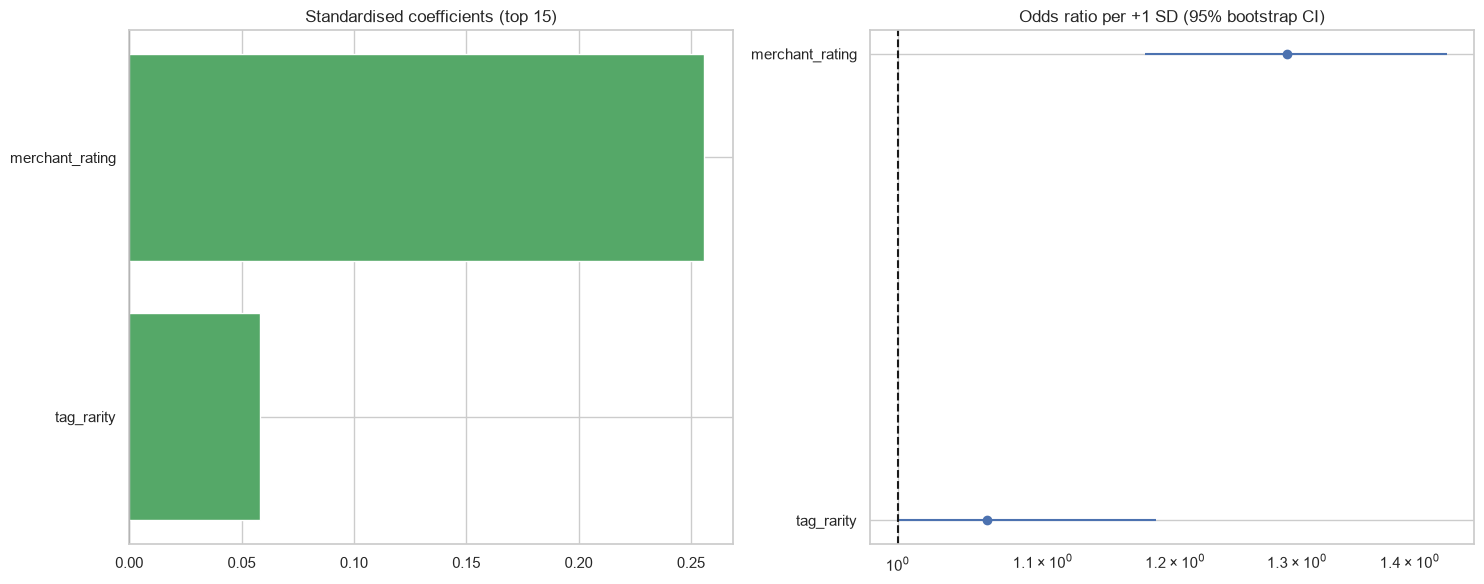

In [13]:
t = coef_tbl[coef_tbl["coef_per_sd"].abs() > 1e-8].head(15).iloc[::-1]
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
ax[0].barh(t.index, t["coef_per_sd"], color=np.where(t["coef_per_sd"] > 0, "#55a868", "#c44e52")); ax[0].axvline(0, color="k", lw=.8); ax[0].set_title("Standardised coefficients (top 15)")
ax[1].errorbar(t["odds_ratio_per_sd"], range(len(t)), xerr=[t["odds_ratio_per_sd"] - t["or_ci_low"], t["or_ci_high"] - t["odds_ratio_per_sd"]], fmt="o", color="#4c72b0"); ax[1].set_yticks(range(len(t))); ax[1].set_yticklabels(t.index)
ax[1].axvline(1, color="k", ls="--"); ax[1].set_xscale("log"); ax[1].set_title("Odds ratio per +1 SD (95% bootstrap CI)"); plt.tight_layout(); plt.show()

## 8. Save outputs

In [14]:
prob_all = pd.Series(np.nan, index=F.index); prob_all[Xtr.index] = oof; prob_all[Xte.index] = p_te
out = pd.concat([df[[id_col]] if id_col else pd.DataFrame(index=F.index), y, pd.Series(np.where(F.index.isin(Xte.index), "holdout", "train"), index=F.index, name="split"), F,
                 prob_all.rename("recommend_prob_oof"), (prob_all >= t_star).astype(int).rename("recommend_pred")], axis=1)
out_path = PROC / "womens_clothing_recommendation_features.csv"; out.to_csv(out_path, index=False)
grid.round(6).to_csv(REPORTS / "task_30_balancing_comparison.csv", index=False); metrics_tbl.round(6).to_csv(REPORTS / "task_30_model_metrics.csv", index=False)
coef_tbl.round(6).reset_index(names="feature").to_csv(REPORTS / "task_30_logistic_coefficients.csv", index=False); thr_tbl.round(6).to_csv(REPORTS / "task_30_threshold_analysis.csv", index=False)
m0 = metrics_tbl.iloc[1]
status = pd.DataFrame([{"task": "Task 30 - Logistic regression (recommendation)", "status": "completed", "run_at": datetime.now().isoformat(timespec="seconds"), "input_file": src.name,
    "rows_used": len(out), "recommend_threshold_rating": round(thr, 4), "positive_rate": round(y.mean(), 4), "n_features": F.shape[1], "final_sampler": final_cfg["sampler"], "final_penalty": final_cfg["penalty"],
    "final_C": round(final_cfg["C"], 5), "nonzero_coefficients": int((coef.abs() > 1e-8).sum()), "cv_pr_auc": round(final_cfg["cv_pr_auc"], 4), "holdout_roc_auc": round(m0["roc_auc"], 4),
    "holdout_pr_auc": round(m0["pr_auc"], 4), "holdout_f1_tuned": round(m0["f1"], 4), "rf_reference_roc_auc": round(metrics_tbl.iloc[3]["roc_auc"], 4), "tuned_threshold": round(t_star, 3), "output_dataset": out_path.name}])
status.to_csv(REPORTS / "task_30_analysis_status.csv", index=False); status.T

,0
task,Task 30 - Logistic regression (recommendation)
status,completed
run_at,2026-11-27T16:14:29
input_file,womens_clothing_rating_sentiment_encoded.csv
rows_used,1211
recommend_threshold_rating,4.04
positive_rate,0.308
n_features,26
final_sampler,none
final_penalty,ElasticNet
